# Catching fraudsters with statistics

**Question.** Can we recover each detective tool’s accusation from the ledger alone? Each section derives the calculation in pandas, NumPy, SciPy, or scikit-learn, draws the evidence, and checks the implicated IDs against the game’s `run_tool`. The named level supplies the relevant fraud pattern; summary remains descriptive.

In [1]:
import sys
sys.path.insert(0, "../backend")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chisquare, chi2_contingency, binomtest, ttest_1samp
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import IsolationForest
from auditor.generator.base import (CATEGORY_PROFILES, HONEST_SIGMA, HONEST_Z_CLIP, CEO_MULTIPLIER, make_suspects, make_honest_transactions)
from auditor.generator.cases import build_case, build_honest_case, CASE_START
from auditor.generator.schemes import inject, SCHEME_CATCHERS
from auditor.generator.red_herrings import add_herring
from auditor.tools.registry import run_tool, TOOLS
sns.set_theme(style="darkgrid", context="notebook", palette=["#F5A524", "#4CC9F0", "#E5484D", "#3DD68C"])
plt.rcParams.update({"figure.facecolor":"#0E1117", "axes.facecolor":"#161B24", "axes.labelcolor":"#E8E6E1", "text.color":"#E8E6E1", "xtick.color":"#E8E6E1", "ytick.color":"#E8E6E1", "grid.color":"#394252", "savefig.facecolor":"#0E1117"})
AMBER, CYAN, RED = "#F5A524", "#4CC9F0", "#E5484D"

In [2]:
cases={level:build_case(level,seed=7) for level in range(1,7)}
def check(tool, level, hand, params=None):
    analysis,_,_=run_tool(tool,cases[level].df,params or {})
    assert sorted(hand)==analysis.implicates,(tool,hand,analysis.implicates)
    print(f"{tool} · level {level}: hand {sorted(hand)} = game {analysis.implicates}; culprit {cases[level].truth.fraudster_id}")
    return analysis

## 1. Summary — descriptive statistics

**Question.** Who spent the most? `describe()` gives count, centre, spread, and extrema; totals are a separate sum. This tool deliberately accuses nobody because high spending can be authorized.

             count      mean       std     min    median        max  \
employee_id                                                           
E1           190.0  39992.83  59212.32  214.02  14432.25  294367.56   
E2           203.0   9980.85  30861.02   57.48   1837.18  415743.59   
E3           192.0   9131.33  13249.14   36.79   2926.92   85897.71   
E4           195.0   9237.47  13532.29   44.19   2468.09   85523.15   
E5           210.0   9953.78  13466.95   41.35   3093.46   78648.28   

                  total  
employee_id              
E1           7598638.41  
E2           2026111.62  
E3           1753214.58  
E4           1801307.15  
E5           2090293.15  


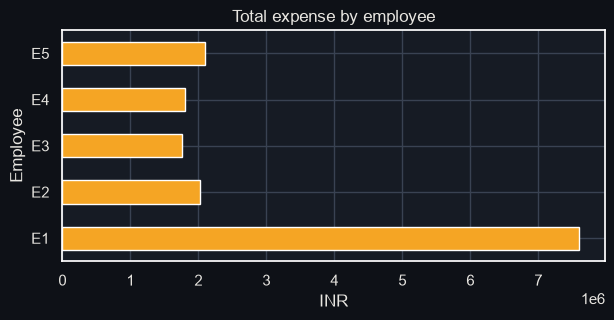

summary · level 1: hand [] = game []; culprit E2


In [3]:
df=cases[1].df
summary=df.groupby("employee_id").amount.describe()[["count","mean","std","min","50%","max"]].rename(columns={"50%":"median"}).round(2)
summary["total"]=df.groupby("employee_id").amount.sum().round(2)
print(summary)
fig,ax=plt.subplots(figsize=(7,3)); summary.total.plot.barh(ax=ax,color=AMBER); ax.set(title="Total expense by employee",xlabel="INR",ylabel="Employee"); plt.show()
a=check("summary",1,[])
pd.testing.assert_frame_equal(summary.reset_index(),a.table)

**Takeaway.** The top spender is a lead for investigation, not a verdict.

## 2. Groupby — exclusive vendor use

**Question.** Who repeatedly pays a vendor nobody else uses? A vendor crosstab counts claims. The vendor mode uses exclusivity because normal people have favourite vendors. Other groupings use a 2×k chi-square independence test against everyone else, with p < 0.001.

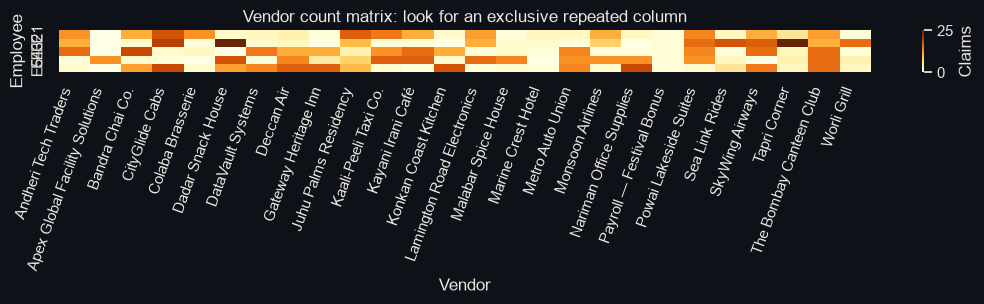

Exclusive-vendor claim counts: {'E1': 0, 'E2': 0, 'E3': 0, 'E4': 13, 'E5': 0}
groupby · level 6: hand ['E4'] = game ['E4']; culprit E4


Analysis(title='Pattern Matrix · by vendor', summary='Stands out: E4 — claims at vendors nobody else uses.', stats={'exclusive_E1': 0, 'exclusive_E2': 0, 'exclusive_E3': 0, 'exclusive_E4': 13, 'exclusive_E5': 0}, implicates=['E4'], table=vendor employee_id  Andheri Tech Traders  Apex Global Facility Solutions  \
0               E1                    13                               0   
1               E2                    11                               0   
2               E3                    16                               0   
3               E4                     1                              13   
4               E5                     2                               0   

vendor  Bandra Chai Co.  CityGlide Cabs  Colaba Brasserie  Dadar Snack House  \
0                    11              18                13                  2   
1                     2              20                 1                 25   
2                    19               2                 3        

In [4]:
df=cases[6].df
matrix=pd.crosstab(df.employee_id,df.vendor)
exclusive=matrix.loc[:,(matrix.gt(0).sum(axis=0)==1)].sum(axis=1)
hand=exclusive[exclusive>=5].index.tolist()
fig,ax=plt.subplots(figsize=(11,3.2)); sns.heatmap(matrix,cmap="YlOrBr",ax=ax,cbar_kws={"label":"Claims"}); ax.set(title="Vendor count matrix: look for an exclusive repeated column",xlabel="Vendor",ylabel="Employee"); plt.xticks(rotation=70,ha="right"); plt.tight_layout(); plt.show()
print("Exclusive-vendor claim counts:",exclusive.to_dict())
check("groupby",6,hand,{"by":"vendor"})

**Takeaway.** An exclusive vendor used at least five times is stronger evidence than an ordinary favourite.

## 3. Z-score — comparable claims

**Question.** Which claims differ from the *same person’s same category*? Since category amounts are log-normal, compute `z=(log10(amount)−group mean)/group sample SD`. A claim beyond |z| > 3 implicates its owner. Raw global rupee z-scores would mix categories and the CEO.

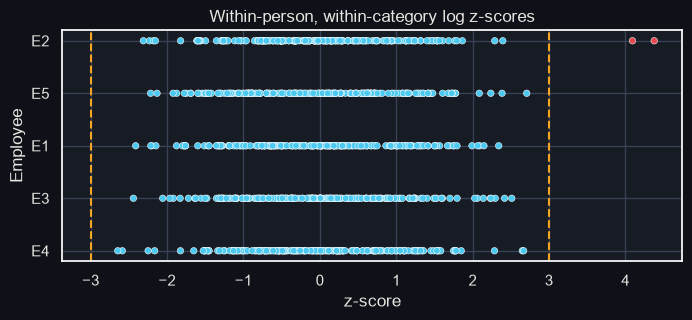

zscore · level 1: hand ['E2'] = game ['E2']; culprit E2


Analysis(title='Z-Score Scan · per employee', summary='2 claim(s) more than 3 standard deviations from that person’s own normal. Flagged: E2.', stats={'scope': 'per_employee', 'threshold': 3.0, 'flagged_rows': 2, 'flagged_E2': 2}, implicates=['E2'], table=     txn_id employee_id     category                vendor     amount     z
855  T00856          E2  client_meal           Worli Grill   30201.22  4.09
874  T00875          E2    equipment  Andheri Tech Traders  415743.59  4.38, plot_data={'employee': ['E2', 'E5', 'E5', 'E2', 'E2', 'E1', 'E3', 'E5', 'E5', 'E2', 'E3', 'E3', 'E2', 'E4', 'E5', 'E2', 'E5', 'E1', 'E1', 'E2', 'E1', 'E3', 'E4', 'E2', 'E2', 'E1', 'E2', 'E5', 'E3', 'E1', 'E5', 'E5', 'E2', 'E5', 'E5', 'E5', 'E5', 'E5', 'E3', 'E1', 'E1', 'E5', 'E5', 'E1', 'E2', 'E4', 'E5', 'E3', 'E1', 'E2', 'E4', 'E2', 'E5', 'E2', 'E4', 'E2', 'E3', 'E4', 'E1', 'E5', 'E4', 'E1', 'E5', 'E3', 'E3', 'E2', 'E1', 'E3', 'E5', 'E1', 'E2', 'E1', 'E1', 'E1', 'E2', 'E1', 'E5', 'E2', 'E5', 'E4', 'E1', 'E1',

In [5]:
df=cases[1].df
logs=np.log10(df.amount); groups=logs.groupby([df.employee_id,df.category]); z=(logs-groups.transform("mean"))/groups.transform("std")
hand=sorted(df.loc[z.abs()>3,"employee_id"].unique())
fig,ax=plt.subplots(figsize=(8,3)); sns.scatterplot(x=z,y=df.employee_id,hue=z.abs()>3,palette={False:CYAN,True:RED},legend=False,ax=ax,s=22); ax.axvline(3,color=AMBER,ls="--"); ax.axvline(-3,color=AMBER,ls="--"); ax.set(title="Within-person, within-category log z-scores",xlabel="z-score",ylabel="Employee"); plt.show()
check("zscore",1,hand,{"scope":"per_employee","threshold":3.0})

**Takeaway.** This baseline exposes the oversized invoice without treating the CEO’s normal scale as guilt.

## 4. Box plot — Tukey far-out fences

**Question.** Is any claim huge relative to its owner’s usual claim in that category? Subtract each employee–category median on the log scale. For each employee, flag values above `Q3 + 3×(Q3−Q1)`; this is a far-out fence, stricter than the usual 1.5×IQR whisker.

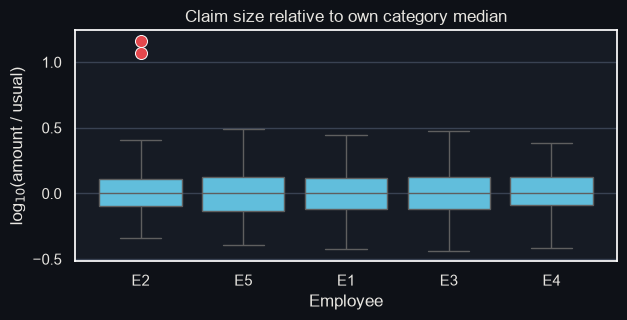

iqr_box · level 1: hand ['E2'] = game ['E2']; culprit E2


Analysis(title='Box & Whisker', summary="2 claim(s) beyond the far-out fence (Q3 + 3·IQR) of the person's own spending pattern. Flagged: E2.", stats={'flagged_rows': 2, 'max_times_usual_E1': 2.7630100298081284, 'max_times_usual_E2': 14.545745751722306, 'max_times_usual_E3': 3.0142286614818703, 'max_times_usual_E4': 3.073619874336441, 'max_times_usual_E5': 3.1105472074716083}, implicates=['E2'], table=     txn_id employee_id     category                vendor     amount  \
855  T00856          E2  client_meal           Worli Grill   30201.22   
874  T00875          E2    equipment  Andheri Tech Traders  415743.59   

     times_usual  
855         14.5  
874         11.7  , plot_data={'employee': ['E2', 'E5', 'E5', 'E2', 'E2', 'E1', 'E3', 'E5', 'E5', 'E2', 'E3', 'E3', 'E2', 'E4', 'E5', 'E2', 'E5', 'E1', 'E1', 'E2', 'E1', 'E3', 'E4', 'E2', 'E2', 'E1', 'E2', 'E5', 'E3', 'E1', 'E5', 'E5', 'E2', 'E5', 'E5', 'E5', 'E5', 'E5', 'E3', 'E1', 'E1', 'E5', 'E5', 'E1', 'E2', 'E4', 'E5', 'E3', 'E1', 

In [6]:
df=cases[1].df
logs=np.log10(df.amount); relative=logs-logs.groupby([df.employee_id,df.category]).transform("median")
q1=relative.groupby(df.employee_id).transform(lambda x:x.quantile(.25)); q3=relative.groupby(df.employee_id).transform(lambda x:x.quantile(.75))
out=relative>q3+3*(q3-q1); hand=sorted(df.loc[out,"employee_id"].unique())
fig,ax=plt.subplots(figsize=(7,3)); sns.boxplot(x=df.employee_id,y=relative,showfliers=False,color=CYAN,ax=ax); sns.scatterplot(x=df.loc[out,"employee_id"],y=relative[out],color=RED,s=75,ax=ax); ax.set(title="Claim size relative to own category median",xlabel="Employee",ylabel="log$_{10}$(amount / usual)"); plt.show()
check("iqr_box",1,hand)

**Takeaway.** A far-out point is useful evidence when the baseline is local to that employee.

## 5. Duplicates — receipt twins

**Question.** Did the same person submit the same vendor and amount again within seven days? Join claims to themselves, retain positive day gaps ≤7, and require at least three pairs. The invoice ID is intentionally absent from the join.

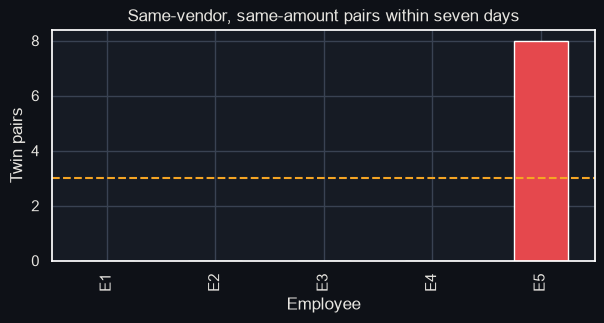

duplicates · level 2: hand ['E5'] = game ['E5']; culprit E5


Analysis(title='Twin Finder', summary='8 twin invoice pair(s): same person, same vendor, same amount, within 7 days. Repeat offenders: E5.', stats={'twin_pairs': 8, 'pairs_E5': 8}, implicates=['E5'], table=  employee_id                vendor    amount      date_a      date_b
0          E5     Dadar Snack House    124.12  2026-08-27  2026-08-28
1          E5            Deccan Air  26982.13  2026-09-08  2026-09-11
2          E5     DataVault Systems  25726.38  2026-09-09  2026-09-11
3          E5  Konkan Coast Kitchen   2573.97  2026-10-07  2026-10-09
4          E5     Kayani Irani Café     97.50  2026-10-07  2026-10-09
5          E5     DataVault Systems  26323.31  2026-10-16  2026-10-19
6          E5      Colaba Brasserie   2508.65  2026-10-16  2026-10-19
7          E5  Konkan Coast Kitchen   1440.27  2026-11-02  2026-11-03, plot_data={'pairs': [{'employee_id': 'E5', 'vendor': np.str_('Dadar Snack House'), 'amount': 124.12, 'date_a': '2026-08-27', 'date_b': '2026-08-28'}, {'employee_id

In [7]:
df=cases[2].df
claims=df[["txn_id","employee_id","vendor","amount","date"]].assign(date=pd.to_datetime(df.date))
pairs=claims.merge(claims,on=["employee_id","vendor","amount"],suffixes=("_a","_b"))
gap=(pairs.date_b-pairs.date_a).dt.days; twins=pairs[gap.between(1,7)]
counts=twins.employee_id.value_counts(); hand=sorted(counts[counts>=3].index)
fig,ax=plt.subplots(figsize=(7,3)); counts.reindex(sorted(df.employee_id.unique()),fill_value=0).plot.bar(ax=ax,color=RED); ax.axhline(3,color=AMBER,ls="--"); ax.set(title="Same-vendor, same-amount pairs within seven days",xlabel="Employee",ylabel="Twin pairs"); plt.show()
check("duplicates",2,hand)

**Takeaway.** Reissued IDs do not change the repeated economic transaction.

## 6. Benford — a digit fingerprint

**Question.** Are a suspect’s first digits too far from `P(d)=log10(1+1/d)`? For each employee with at least 50 claims, Pearson’s chi-square statistic compares observed and expected digit counts. The game uses a deliberately strict p < 10⁻⁵ threshold.

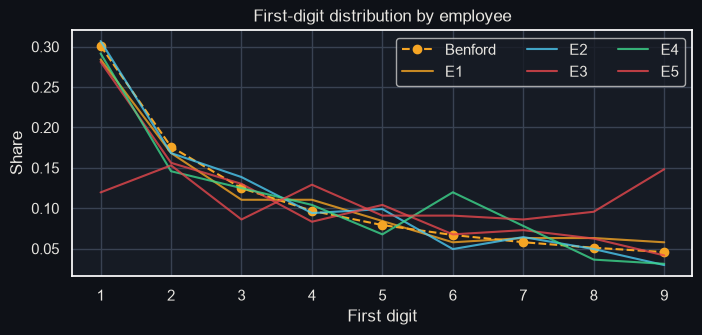

Chi-square p-values: {'E1': np.float64(0.9640605297862684), 'E2': np.float64(0.889468481180755), 'E3': np.float64(0.8666402624900045), 'E4': np.float64(0.12937940519474087), 'E5': np.float64(6.131546664053976e-16)}
benford · level 3: hand ['E5'] = game ['E5']; culprit E5


Analysis(title="Benford's Law", summary='Real money starts with a 1 about 30% of the time. Ledgers that break the pattern (chi-square p < 0.00001): E5.', stats={'n_E1': 190, 'p_E1': 0.9640605297862684, 'verdict_E1': 'conforms', 'n_E2': 202, 'p_E2': 0.889468481180755, 'verdict_E2': 'conforms', 'n_E3': 192, 'p_E3': 0.8666402624900045, 'verdict_E3': 'conforms', 'n_E4': 192, 'p_E4': 0.12937940519474087, 'verdict_E4': 'conforms', 'n_E5': 209, 'p_E5': 6.131546664053976e-16, 'verdict_E5': 'suspicious'}, implicates=['E5'], table=   digit  benford      E1      E2      E3      E4      E5
0      1   0.3010  0.2842  0.3069  0.2812  0.2917  0.1196
1      2   0.1761  0.1684  0.1683  0.1562  0.1458  0.1531
2      3   0.1249  0.1105  0.1386  0.1302  0.1250  0.0861
3      4   0.0969  0.1105  0.0941  0.0833  0.1042  0.1292
4      5   0.0792  0.0842  0.0990  0.1042  0.0677  0.0909
5      6   0.0669  0.0579  0.0495  0.0677  0.1198  0.0909
6      7   0.0580  0.0632  0.0644  0.0729  0.0781  0.0861
7      8 

In [8]:
df=cases[3].df
digits=np.floor(df.amount/10**np.floor(np.log10(df.amount))).astype(int)
expected=np.log10(1+1/np.arange(1,10)); digit_counts=pd.crosstab(df.employee_id,digits).reindex(columns=range(1,10),fill_value=0)
pvals={e:chisquare(row.to_numpy(),expected*row.sum()).pvalue for e,row in digit_counts.iterrows() if row.sum()>=50}
hand=sorted(e for e,p in pvals.items() if p<1e-5)
fig,ax=plt.subplots(figsize=(8,3.2)); ax.plot(range(1,10),expected,color=AMBER,ls="--",marker="o",label="Benford")
for e,row in digit_counts.iterrows(): ax.plot(range(1,10),row/row.sum(),alpha=.8,label=e,color=RED if e==cases[3].truth.fraudster_id else None)
ax.set(title="First-digit distribution by employee",xlabel="First digit",ylabel="Share",xticks=range(1,10)); ax.legend(ncol=3); plt.show()
print("Chi-square p-values:",pvals)
check("benford",3,hand)

**Takeaway.** The threshold tests a distribution, not a single suspicious number; small samples stay inconclusive.

## 7. Timeline — weekend rate

**Question.** Who files too many claims when the office is closed? For each employee, estimate the null weekend rate from *everyone else*, then use a one-sided exact binomial test. The rule is p < 0.001.

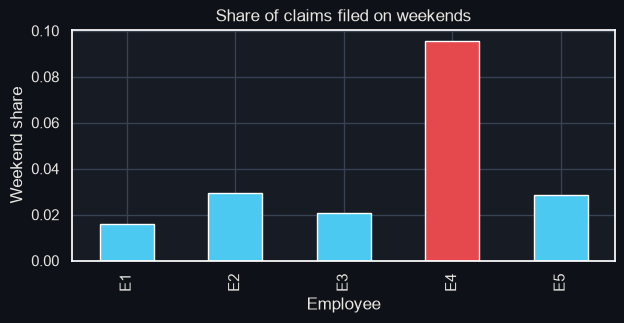

One-sided binomial p-values: {'E1': np.float64(0.9913105676047183), 'E2': np.float64(0.8437510084249072), 'E3': np.float64(0.968323132660554), 'E4': np.float64(1.908430586435322e-07), 'E5': np.float64(0.8706237025393075)}
timeseries · level 4: hand ['E4'] = game ['E4']; culprit E4


Analysis(title='Timeline · daily', summary='Typical employee files 3% of claims on weekends. Card active while the office sleeps: E4.', stats={'company_median_weekend_share': 0.0286, 'weekend_share_E1': 0.0157, 'weekend_share_E2': 0.0296, 'weekend_share_E3': 0.0207, 'weekend_share_E4': 0.0957, 'weekend_share_E5': 0.0286, 'weekend_claims_E1': 3, 'weekend_claims_E2': 6, 'weekend_claims_E3': 4, 'weekend_claims_E4': 20, 'weekend_claims_E5': 6, 'p_E1': 0.9913105676047183, 'p_E2': 0.8437510084249072, 'p_E3': 0.968323132660554, 'p_E4': 1.908430586435322e-07, 'p_E5': 0.8706237025393075}, implicates=['E4'], table=  employee_id  weekend_share  weekend_claims
0          E1         0.0157               3
1          E2         0.0296               6
2          E3         0.0207               4
3          E4         0.0957              20
4          E5         0.0286               6, plot_data={'dates': ['2026-08-17', '2026-08-18', '2026-08-19', '2026-08-20', '2026-08-21', '2026-08-22', '2026-08-23'

In [9]:
df=cases[4].df
dated=df.assign(weekend=pd.to_datetime(df.date).dt.day_of_week>=5)
pvals={e:binomtest(int(rows.weekend.sum()),len(rows),dated.loc[dated.employee_id!=e,"weekend"].mean(),alternative="greater").pvalue for e,rows in dated.groupby("employee_id")}
hand=sorted(e for e,p in pvals.items() if p<.001)
shares=dated.groupby("employee_id").weekend.mean()
fig,ax=plt.subplots(figsize=(7,3)); shares.plot.bar(ax=ax,color=[RED if e in hand else CYAN for e in shares.index]); ax.set(title="Share of claims filed on weekends",xlabel="Employee",ylabel="Weekend share"); plt.show()
print("One-sided binomial p-values:",pvals)
check("timeseries",4,hand,{"freq":"D"})

**Takeaway.** A company-wide weekday bonus cluster does not mimic one employee’s repeated weekend activity.

## 8. Regression — expense against deal size

**Question.** Does one employee consistently spend more than their deals predict? Fit ordinary least squares on `log10(expense)` against `log10(revenue)`, divide residuals by their population SD, then use a one-sided one-sample t-test for mean residual > 0. The game implicates p < 0.001.

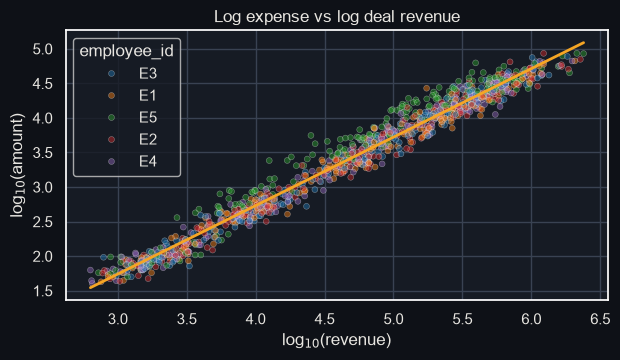

Mean residual p-values: {'E1': np.float64(0.9999965401292312), 'E2': np.float64(0.9999975372144827), 'E3': np.float64(0.9999881724648872), 'E4': np.float64(0.989431384954586), 'E5': np.float64(4.220313841730259e-21)}


regression · level 5: hand ['E5'] = game ['E5']; culprit E5


Analysis(title='Margin Model', summary='Regression explains 97% of expense size from deal revenue. Living above the line (t-test p < 0.001): E5.', stats={'slope': 0.9906242756296961, 'intercept': -1.2305906203373942, 'r2': 0.9721806249676135, 'mean_resid_E1': -0.2707, 'p_E1': 0.9999965401292312, 'mean_resid_E2': -0.2669, 'p_E2': 0.9999975372144827, 'mean_resid_E3': -0.2459, 'p_E3': 0.9999881724648872, 'mean_resid_E4': -0.136, 'p_E4': 0.989431384954586, 'mean_resid_E5': 0.8548, 'p_E5': 4.220313841730259e-21}, implicates=['E5'], table=  employee_id  mean_residual       p_value
0          E1        -0.2707  9.999965e-01
1          E2        -0.2669  9.999975e-01
2          E3        -0.2459  9.999882e-01
3          E4        -0.1360  9.894314e-01
4          E5         0.8548  4.220314e-21, plot_data={'x': [4.7052, 5.2141, 5.8245, 3.5885, 5.1626, 6.22, 5.0994, 5.6299, 3.4984, 3.1649, 4.8253, 4.2126, 4.3687, 5.8717, 3.9897, 3.2807, 4.7963, 4.0609, 3.9811, 6.089, 6.0354, 2.8593, 3.2137, 3.98

In [10]:
df=cases[5].df
x=np.log10(df[["revenue"]].to_numpy()); y=np.log10(df.amount.to_numpy())
model=LinearRegression().fit(x,y); residual=(y-model.predict(x)); standardized=pd.Series(residual/residual.std(),index=df.index)
pvals={e:ttest_1samp(r,0,alternative="greater").pvalue for e,r in standardized.groupby(df.employee_id)}
hand=sorted(e for e,p in pvals.items() if p<.001)
fig,ax=plt.subplots(figsize=(7,3.5)); sns.scatterplot(x=x[:,0],y=y,hue=df.employee_id,palette="tab10",alpha=.45,s=18,ax=ax); xs=np.linspace(x.min(),x.max(),100); ax.plot(xs,model.predict(xs.reshape(-1,1)),color=AMBER,lw=2,label="OLS fit"); ax.set(title="Log expense vs log deal revenue",xlabel="log$_{10}$(revenue)",ylabel="log$_{10}$(amount)"); plt.show()
print("Mean residual p-values:",pvals)
check("regression",5,hand)

**Takeaway.** Consistently positive residuals reveal padded expenses even when individual invoices look plausible.

## 9. Isolation Forest — unusual combinations

**Question.** Who owns too many unusual claims? Features are log size relative to the employee–category median, hour, and vendor popularity. A 200-tree IsolationForest with 2% contamination and seed 0 labels unusual rows. Implicate an employee only with at least six flagged rows and a flagged share above three times the median employee share.

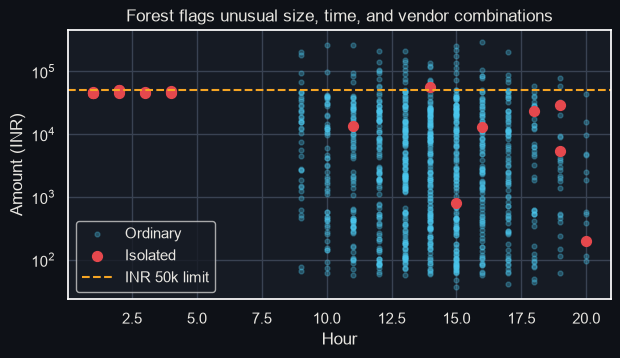

             flagged_count  flagged_share
employee_id                              
E1                       3       0.015707
E2                       1       0.004902
E3                       1       0.005181
E4                      15       0.071770
E5                       1       0.004739


isoforest · level 6: hand ['E4'] = game ['E4']; culprit E4


Analysis(title='Anomaly Hunter · Isolation Forest', summary='The forest isolated 21 strange claims. Owning far more than their share: E4.', stats={'flagged_rows': 21, 'flagged_E1': 3, 'flagged_E2': 1, 'flagged_E3': 1, 'flagged_E4': 15, 'flagged_E5': 1, 'flagged_share_E1': 0.0157, 'flagged_share_E2': 0.0049, 'flagged_share_E3': 0.0052, 'flagged_share_E4': 0.0718, 'flagged_share_E5': 0.0047}, implicates=['E4'], table=     txn_id employee_id                          vendor    amount  hour  \
807  T00808          E4  Apex Global Facility Solutions  45334.11     1   
146  T00147          E4  Apex Global Facility Solutions  45411.65     1   
445  T00446          E4  Apex Global Facility Solutions  46564.08     1   
495  T00496          E4  Apex Global Facility Solutions  46170.42     1   
601  T00602          E4  Apex Global Facility Solutions  49938.10     2   
997  T00998          E4  Apex Global Facility Solutions  49780.11     2   
903  T00904          E4  Apex Global Facility Solutions 

In [11]:
df=cases[6].df
log_amount=np.log10(df.amount)
features=pd.DataFrame({"unusual_size":log_amount-log_amount.groupby([df.employee_id,df.category]).transform("median"),"hour":df.hour,"vendor_popularity":df.vendor.map(df.vendor.value_counts(normalize=True))})
forest=IsolationForest(n_estimators=200,contamination=.02,random_state=0)
flagged=forest.fit_predict(features)==-1
share=pd.Series(flagged,index=df.index).groupby(df.employee_id).mean(); count=pd.Series(flagged,index=df.index).groupby(df.employee_id).sum()
hand=sorted(share[(count>=6)&(share>3*share.median())].index)
fig,ax=plt.subplots(figsize=(7,3.5)); ax.scatter(df.hour[~flagged],df.amount[~flagged],s=12,alpha=.3,color=CYAN,label="Ordinary"); ax.scatter(df.hour[flagged],df.amount[flagged],s=50,color=RED,label="Isolated"); ax.axhline(50000,color=AMBER,ls="--",label="INR 50k limit"); ax.set(xlabel="Hour",ylabel="Amount (INR)",yscale="log",title="Forest flags unusual size, time, and vendor combinations"); ax.legend(); plt.show()
print(pd.DataFrame({"flagged_count":count,"flagged_share":share}))
check("isoforest",6,hand)

**Takeaway.** Isolation is a multivariate clue. The share and count rules keep a handful of odd honest claims from naming a culprit.

## Is the game fair?

**Question.** Across seeds 0–19, how often does a matching-level tool identify the actual fraudster with at most two implicated employees? The heatmap includes all nine tools; pale cells for non-catching tools are descriptive rather than contract failures. The table below runs every tool on twenty honest companies with both red herrings and reports the fraction with *no* implicated employee.

The stated contract is ≥95% for each catching tool and ≥90% no-accusation rate on honest ledgers. We compute the rates rather than presuming the implementation meets them.

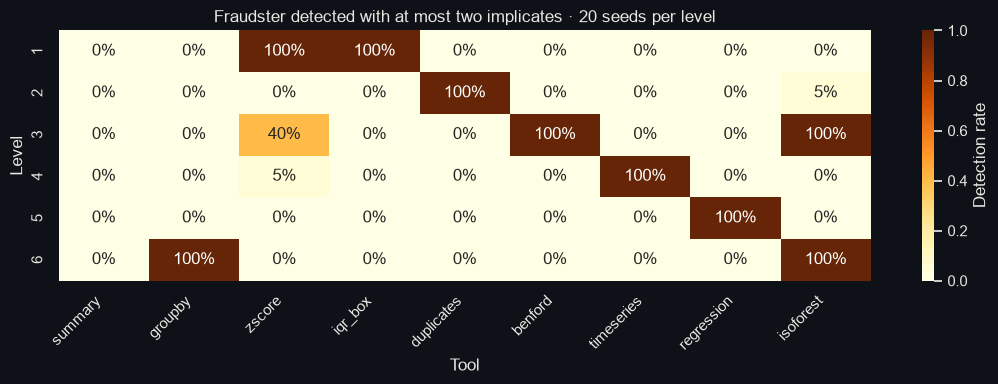

L1 zscore: 100% (target ≥95%)
L1 iqr_box: 100% (target ≥95%)
L2 duplicates: 100% (target ≥95%)
L3 benford: 100% (target ≥95%)
L4 timeseries: 100% (target ≥95%)
L5 regression: 100% (target ≥95%)
L6 isoforest: 100% (target ≥95%)
L6 groupby: 100% (target ≥95%)


In [12]:
tools=["summary","groupby","zscore","iqr_box","duplicates","benford","timeseries","regression","isoforest"]
params={"groupby":{"by":"vendor"},"zscore":{"scope":"per_employee"},"timeseries":{"freq":"D"}}
# The groupby catcher uses vendor exclusivity; other params are their documented defaults.
rates=pd.DataFrame(index=range(1,7),columns=tools,dtype=float)
for level in rates.index:
    hits={t:0 for t in tools}
    for seed in range(20):
        case=build_case(level,seed)
        for tool in tools:
            result=TOOLS[tool].analyze(case.df,**params.get(tool,{}))
            hits[tool]+=case.truth.fraudster_id in result.implicates and len(result.implicates)<=2
    rates.loc[level]=pd.Series(hits)/20
fig,ax=plt.subplots(figsize=(11,4)); sns.heatmap(rates,annot=True,fmt=".0%",cmap="YlOrBr",vmin=0,vmax=1,ax=ax,cbar_kws={"label":"Detection rate"}); ax.set(title="Fraudster detected with at most two implicates · 20 seeds per level",xlabel="Tool",ylabel="Level"); plt.xticks(rotation=45,ha="right"); plt.tight_layout(); plt.show()
for level,scheme in enumerate(["big_invoice","duplicates","fabricated","weekend","inflated_ratio","under_limit"],1):
    for tool in SCHEME_CATCHERS[scheme]:
        print(f"L{level} {tool}: {rates.loc[level,tool]:.0%} (target ≥95%)")

In [13]:
clear={t:0 for t in tools}
for seed in range(20):
    honest_case=build_honest_case(seed)
    for tool in tools:
        result=TOOLS[tool].analyze(honest_case.df,**params.get(tool,{}))
        clear[tool]+=not result.implicates
false_positive=pd.DataFrame({"tool":tools,"no_accusation_rate":[clear[t]/20 for t in tools]})
false_positive["false_positive_rate"]=1-false_positive.no_accusation_rate
false_positive["meets_90pct_target"]=false_positive.no_accusation_rate>=.90
print(false_positive)
print("All catching rates ≥95%:",all(rates.loc[level,tool]>=.95 for level,scheme in enumerate(["big_invoice","duplicates","fabricated","weekend","inflated_ratio","under_limit"],1) for tool in SCHEME_CATCHERS[scheme]))
print("All honest no-accusation rates ≥90%:",false_positive.meets_90pct_target.all())

         tool  no_accusation_rate  false_positive_rate  meets_90pct_target
0     summary                 1.0                  0.0                True
1     groupby                 1.0                  0.0                True
2      zscore                 0.9                  0.1                True
3     iqr_box                 1.0                  0.0                True
4  duplicates                 1.0                  0.0                True
5     benford                 1.0                  0.0                True
6  timeseries                 1.0                  0.0                True
7  regression                 1.0                  0.0                True
8   isoforest                 1.0                  0.0                True
All catching rates ≥95%: True
All honest no-accusation rates ≥90%: True


**Takeaway.** The matrix measures detection and specificity separately. A strong game tool needs both: catch its intended pattern and avoid naming innocent employees, including the CEO and bonus recipients.